# 04 · Visual model

We train a ResNet18 (pretrained on ImageNet) to recognise six emotions from
face images, using the same speaker split as the audio model.

From each video, we take 8 frames spread evenly over the clip, find the face
with the OpenCV face detector and cut out a square face image (224 × 224). If
no face is found in a frame, we use the face position from the nearest frame.
One validation video (1076_MTI_SAD_XX) has no visible face and is excluded.
The model gives a probability for each emotion per frame, and we average the
8 frames to get one prediction per video.

Training has two stages. Stage 1 trains the whole network; the best validation
result is at epoch 3. Stage 2 continues from that model with a ten times
smaller learning rate. The final model is chosen by validation macro-F1.

**Results:** stage 2, epoch 4. Validation accuracy 64.6% (macro-F1 0.647),
test accuracy 68.0% (macro-F1 0.673). This is the visual model used in the
report.

After the first test evaluation, the face images of 765 test videos were lost
from Google Drive. We recreated them with the same code and evaluated the same
final model again. Accuracy and macro-F1 did not change (68.04%, 0.673), but
one wrongly predicted clip changed from Anger to Fear. The predictions from
this second evaluation are the ones used in the report.

We also tried freezing the BatchNorm layers; it did not improve the validation
result and is not included. The last cell saves the prediction files used in
all analyses. The outputs are from the original run.

In [ ]:
from google.colab import drive
from pathlib import Path

drive.mount("/content/drive")
PROJECT_DIR = Path("/content/drive/MyDrive/Affective Project")
VIDEO_DIR = PROJECT_DIR / "archive"

if PROJECT_DIR.exists():
    for item in sorted(PROJECT_DIR.iterdir()):
        item_type = "Folder" if item.is_dir() else "File"
        print(f"{item_type}: {item.name}")
else:
    print(f"Project folder not found: {PROJECT_DIR}")
    print("Update PROJECT_DIR to match your Google Drive folder.")

Mounted at /content/drive
Folder: face_cache_v1
File: test.csv
File: train.csv
Folder: videos
Folder: visual_final
Folder: visual_resnet18
Folder: visual_resnet18_frozen_bn
Folder: visual_resnet18_low_lr


In [ ]:
import pandas as pd

VIDEO_DIR = PROJECT_DIR / "videos"
TRAIN_CSV = PROJECT_DIR / "train.csv"
TEST_CSV = PROJECT_DIR / "test.csv"

train_df = pd.read_csv(TRAIN_CSV)
test_df = pd.read_csv(TEST_CSV)

print(f"Train rows: {len(train_df)}")
print(f"Test rows: {len(test_df)}")

print("\nFirst 10 items in the video folder:")
for i, item in enumerate(sorted(VIDEO_DIR.iterdir())):
    if i == 10:
        break
    print(item.name)

Train rows: 5890
Test rows: 1552

First 10 items in the video folder:
1001_DFA_ANG_XX.flv
1001_DFA_DIS_XX.flv
1001_DFA_FEA_XX.flv
1001_DFA_HAP_XX.flv
1001_DFA_NEU_XX.flv
1001_DFA_SAD_XX.flv
1001_IEO_ANG_HI.flv
1001_IEO_ANG_LO.flv
1001_IEO_ANG_MD.flv
1001_IEO_DIS_HI.flv


In [ ]:
EMOTION_CODES = {
    "Anger": "ANG",
    "Disgust": "DIS",
    "Fear": "FEA",
    "Happy": "HAP",
    "Neutral": "NEU",
    "Sad": "SAD",
}

INTENSITY_CODES = {
    "Unspecified": "XX",
    "High": "HI",
    "Low": "LO",
    "Medium": "MD",
}

def attach_video_paths(df):
    df = df.copy()

    for column in ["Convention", "Label", "Intesnsity"]:
        df[column] = df[column].astype(str).str.strip()

    emotion = df["Label"].map(EMOTION_CODES)
    intensity = df["Intesnsity"].map(INTENSITY_CODES)

    assert emotion.notna().all(), "Unknown emotion labels found."
    assert intensity.notna().all(), "Unknown intensity labels found."

    df["video_id"] = (
        df["Speaker"].astype(int).astype(str)
        + "_" + df["Convention"]
        + "_" + emotion
        + "_" + intensity
    )

    df["video_path"] = df["video_id"].apply(
        lambda video_id: str(VIDEO_DIR / f"{video_id}.flv")
    )

    return df

train_df = attach_video_paths(train_df)
test_df = attach_video_paths(test_df)

available_files = {
    path.name for path in VIDEO_DIR.iterdir() if path.is_file()
}

for split_name, df in [("Train", train_df), ("Test", test_df)]:
    missing = df[
        ~df["video_id"].add(".flv").isin(available_files)
    ]

    print(f"{split_name}: {len(df)} rows, {len(missing)} missing videos")

    if not missing.empty:
        print(missing[["video_id", "video_path"]].head(10).to_string(index=False))

assert train_df["video_id"].is_unique, "Duplicate train video IDs found."
assert test_df["video_id"].is_unique, "Duplicate test video IDs found."
assert set(train_df["video_id"]).isdisjoint(test_df["video_id"]), \
    "Video overlap found between train and test."
assert set(train_df["Speaker"]).isdisjoint(test_df["Speaker"]), \
    "Speaker overlap found between train and test."

print("\nExample mapping:")
print(train_df[["video_id", "Label", "video_path"]].head().to_string(index=False))

Train: 5890 rows, 0 missing videos
Test: 1552 rows, 0 missing videos

Example mapping:
       video_id   Label                                                          video_path
1001_DFA_ANG_XX   Anger /content/drive/MyDrive/Affective Project/videos/1001_DFA_ANG_XX.flv
1001_DFA_DIS_XX Disgust /content/drive/MyDrive/Affective Project/videos/1001_DFA_DIS_XX.flv
1001_DFA_FEA_XX    Fear /content/drive/MyDrive/Affective Project/videos/1001_DFA_FEA_XX.flv
1001_DFA_HAP_XX   Happy /content/drive/MyDrive/Affective Project/videos/1001_DFA_HAP_XX.flv
1001_DFA_NEU_XX Neutral /content/drive/MyDrive/Affective Project/videos/1001_DFA_NEU_XX.flv


In [ ]:
from sklearn.model_selection import train_test_split


speaker_info = train_df[["Speaker", "Gender"]].drop_duplicates()
assert speaker_info["Speaker"].is_unique, \
    "Some speakers have inconsistent gender labels."


train_speakers, val_speakers = train_test_split(
    speaker_info,
    test_size=0.20,
    stratify=speaker_info["Gender"],
    random_state=42,
)


fit_df = train_df[
    train_df["Speaker"].isin(train_speakers["Speaker"])
].copy()

val_df = train_df[
    train_df["Speaker"].isin(val_speakers["Speaker"])
].copy()

assert set(fit_df["Speaker"]).isdisjoint(val_df["Speaker"])
assert set(fit_df["Speaker"]).isdisjoint(test_df["Speaker"])
assert set(val_df["Speaker"]).isdisjoint(test_df["Speaker"])

for name, df in [
    ("Train", fit_df),
    ("Validation", val_df),
    ("Test", test_df),
]:
    print(f"{name}: {len(df)} videos, {df['Speaker'].nunique()} speakers")

Train: 4667 videos, 57 speakers
Validation: 1223 videos, 15 speakers
Test: 1552 videos, 19 speakers


Video ID: 1001_DFA_ANG_XX
Emotion: Anger
Decoded frames: 67
Frame size: (360, 480, 3)
Selected frame indices: [0, 9, 18, 28, 37, 47, 56, 66]


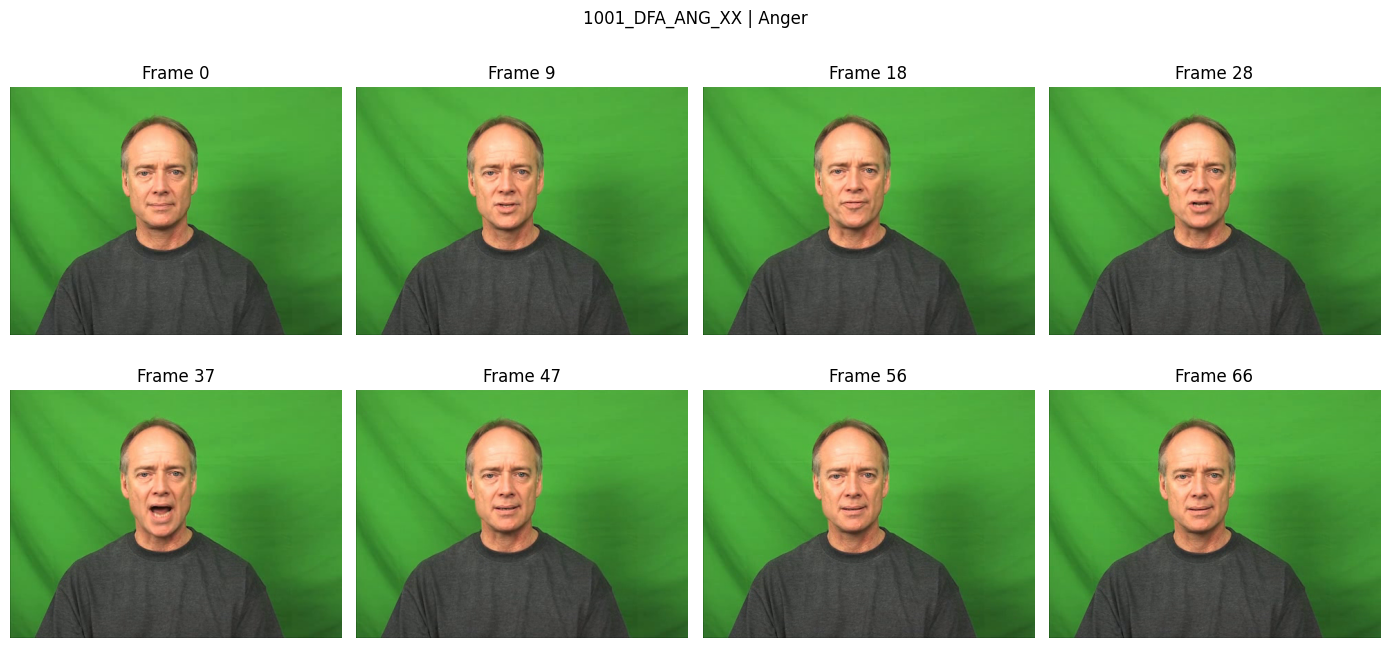

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

sample = fit_df.iloc[0]
video_path = sample["video_path"]

cap = cv2.VideoCapture(video_path)

if not cap.isOpened():
    cap.release()
    raise RuntimeError(f"Could not open video: {video_path}")

frames = []

try:
    while True:
        success, frame = cap.read()
        if not success:
            break
        frames.append(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB))
finally:
    cap.release()

if not frames:
    raise RuntimeError(f"No frames could be decoded: {video_path}")

indices = np.linspace(0, len(frames) - 1, 8, dtype=int)
sampled_frames = [frames[index] for index in indices]

print(f"Video ID: {sample['video_id']}")
print(f"Emotion: {sample['Label']}")
print(f"Decoded frames: {len(frames)}")
print(f"Frame size: {frames[0].shape}")
print(f"Selected frame indices: {indices.tolist()}")

fig, axes = plt.subplots(2, 4, figsize=(14, 7))

for ax, frame, index in zip(axes.flat, sampled_frames, indices):
    ax.imshow(frame)
    ax.set_title(f"Frame {index}")
    ax.axis("off")

fig.suptitle(f"{sample['video_id']} | {sample['Label']}")
plt.tight_layout()
plt.show()

In [ ]:
%pip uninstall -y opencv-python opencv-python-headless opencv-contrib-python opencv-contrib-python-headless
%pip install -q "opencv-python-headless==4.11.0.86"

Found existing installation: opencv-python-headless 4.11.0.86
Uninstalling opencv-python-headless-4.11.0.86:
  Successfully uninstalled opencv-python-headless-4.11.0.86


In [ ]:
import cv2

print("OpenCV version:", cv2.__version__)
print("CascadeClassifier available:", hasattr(cv2, "CascadeClassifier"))

assert hasattr(cv2, "CascadeClassifier"), \
    "Face detector unavailable. Check the installation and restart the session."

OpenCV version: 4.11.0
CascadeClassifier available: True


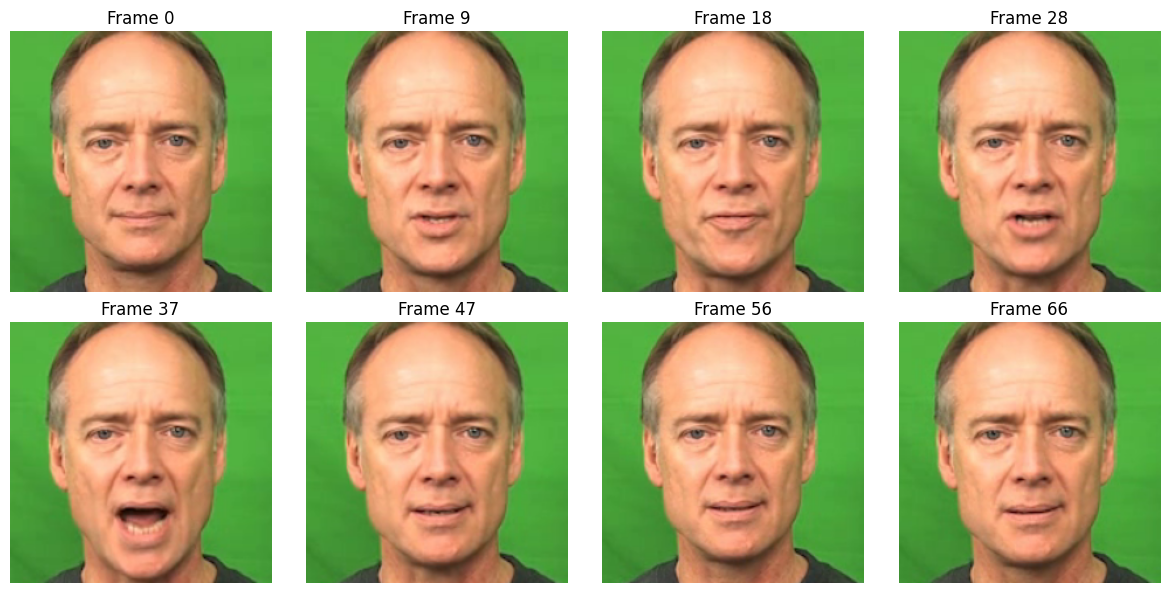

Faces detected: 8/8


In [ ]:
face_detector = cv2.CascadeClassifier(
    cv2.data.haarcascades + "haarcascade_frontalface_default.xml"
)

if face_detector.empty():
    raise RuntimeError("Could not load the face detector.")

face_crops = []
detection_results = []

for frame in sampled_frames:
    gray = cv2.cvtColor(frame, cv2.COLOR_RGB2GRAY)

    boxes = face_detector.detectMultiScale(
        gray,
        scaleFactor=1.1,
        minNeighbors=5,
        minSize=(40, 40),
    )

    if len(boxes) == 0:
        face_crops.append(None)
        detection_results.append("No face detected")
        continue

    x, y, w, h = max(boxes, key=lambda box: box[2] * box[3])

    margin = int(0.15 * max(w, h))
    height, width = frame.shape[:2]

    x1 = max(0, x - margin)
    y1 = max(0, y - margin)
    x2 = min(width, x + w + margin)
    y2 = min(height, y + h + margin)

    crop = frame[y1:y2, x1:x2]
    crop = cv2.resize(crop, (224, 224))

    face_crops.append(crop)
    detection_results.append("Face detected")

fig, axes = plt.subplots(2, 4, figsize=(12, 6))

for ax, crop, index, result in zip(
    axes.flat, face_crops, indices, detection_results
):
    if crop is not None:
        ax.imshow(crop)
    else:
        ax.text(
            0.5, 0.5, "No face detected",
            ha="center", va="center",
            transform=ax.transAxes,
        )

    ax.set_title(f"Frame {index}")
    ax.axis("off")

plt.tight_layout()
plt.show()

detected_count = sum(crop is not None for crop in face_crops)
print(f"Faces detected: {detected_count}/{len(sampled_frames)}")

In [ ]:
import time
from tqdm.auto import tqdm

def sample_video_frames(video_path, num_frames=8):
    cap = cv2.VideoCapture(str(video_path))
    frames = []

    try:
        if not cap.isOpened():
            raise RuntimeError("Could not open video.")

        while True:
            success, frame = cap.read()
            if not success:
                break
            frames.append(frame)
    finally:
        cap.release()

    if not frames:
        raise RuntimeError("No frames decoded.")

    selected = np.linspace(0, len(frames) - 1, num_frames, dtype=int)
    return [frames[i] for i in selected]

pilot_df = (
    fit_df.groupby("Label", group_keys=False)
    .sample(n=5, random_state=42)
)

pilot_results = []
start = time.perf_counter()

for row in tqdm(
    pilot_df.itertuples(index=False),
    total=len(pilot_df),
    desc="Checking face detection",
):
    try:
        selected_frames = sample_video_frames(row.video_path)
        detected = 0

        for frame in selected_frames:
            gray = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)
            boxes = face_detector.detectMultiScale(
                gray,
                scaleFactor=1.1,
                minNeighbors=5,
                minSize=(40, 40),
            )
            detected += int(len(boxes) > 0)

        pilot_results.append({
            "video_id": row.video_id,
            "Label": row.Label,
            "detected_frames": detected,
            "error": "",
        })

    except Exception as exc:
        pilot_results.append({
            "video_id": row.video_id,
            "Label": row.Label,
            "detected_frames": 0,
            "error": str(exc),
        })

pilot_results = pd.DataFrame(pilot_results)
elapsed = time.perf_counter() - start

print(pilot_results.to_string(index=False))
print(f"\nElapsed time: {elapsed:.1f} seconds")
print(
    f"Frames with detected faces: "
    f"{pilot_results['detected_frames'].sum()}/{len(pilot_df) * 8}"
)
print(f"Video read errors: {pilot_results['error'].ne('').sum()}")

Checking face detection:   0%|          | 0/30 [00:00<?, ?it/s]

       video_id   Label  detected_frames error
1082_IWW_ANG_XX   Anger                8      
1080_IWL_ANG_XX   Anger                8      
1006_IWL_ANG_XX   Anger                8      
1067_IEO_ANG_LO   Anger                8      
1006_TAI_ANG_XX   Anger                8      
1078_IWL_DIS_XX Disgust                8      
1066_TAI_DIS_XX Disgust                8      
1040_WSI_DIS_XX Disgust                8      
1016_TAI_DIS_XX Disgust                8      
1035_ITS_DIS_XX Disgust                8      
1059_ITH_FEA_XX    Fear                8      
1054_ITS_FEA_XX    Fear                8      
1073_TAI_FEA_XX    Fear                8      
1080_ITS_FEA_XX    Fear                8      
1053_IWL_FEA_XX    Fear                8      
1083_ITH_HAP_XX   Happy                8      
1008_TAI_HAP_XX   Happy                8      
1038_TIE_HAP_XX   Happy                8      
1003_IWL_HAP_XX   Happy                8      
1080_TIE_HAP_XX   Happy                6      
1089_TSI_NEU_

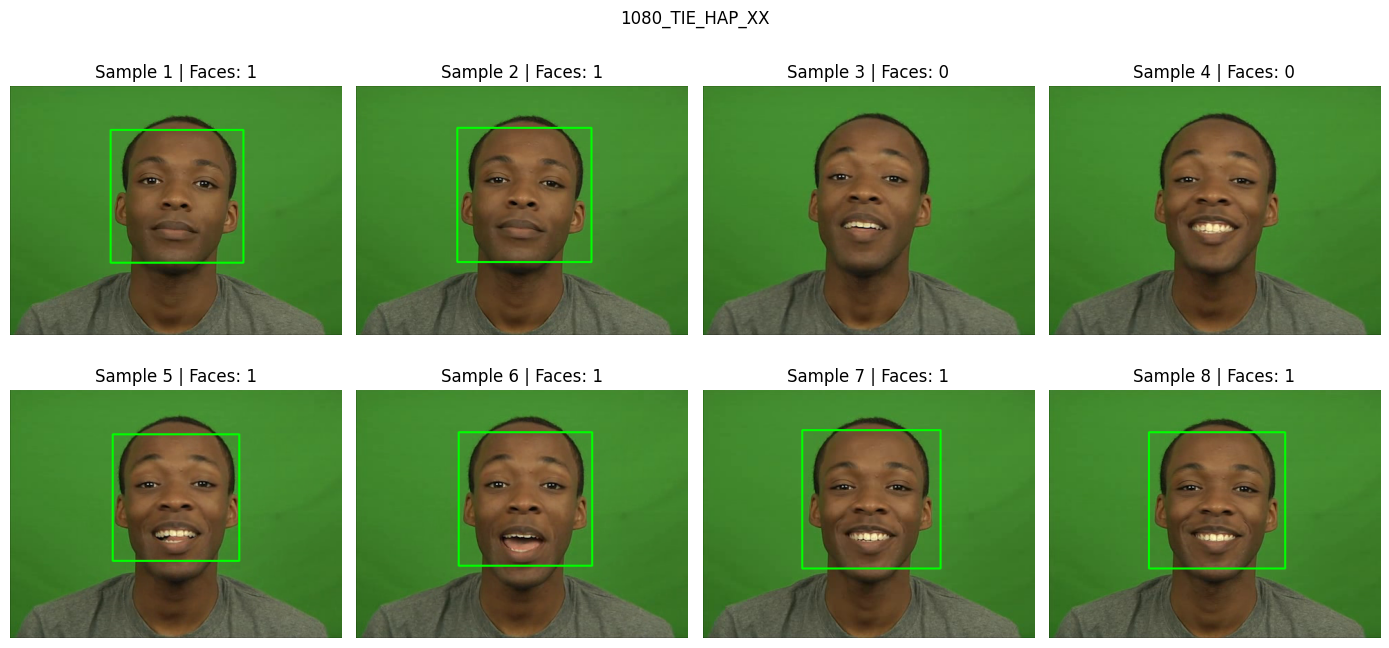

In [ ]:
problem_id = "1080_TIE_HAP_XX"
problem_row = fit_df.loc[fit_df["video_id"] == problem_id].iloc[0]
problem_frames = sample_video_frames(problem_row["video_path"])

fig, axes = plt.subplots(2, 4, figsize=(14, 7))

for position, (ax, frame) in enumerate(zip(axes.flat, problem_frames)):
    gray = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)

    boxes = face_detector.detectMultiScale(
        gray,
        scaleFactor=1.1,
        minNeighbors=5,
        minSize=(40, 40),
    )

    annotated = frame.copy()

    for x, y, w, h in boxes:
        cv2.rectangle(
            annotated,
            (x, y),
            (x + w, y + h),
            (0, 255, 0),
            2,
        )

    ax.imshow(cv2.cvtColor(annotated, cv2.COLOR_BGR2RGB))
    ax.set_title(f"Sample {position + 1} | Faces: {len(boxes)}")
    ax.axis("off")

fig.suptitle(problem_id)
plt.tight_layout()
plt.show()

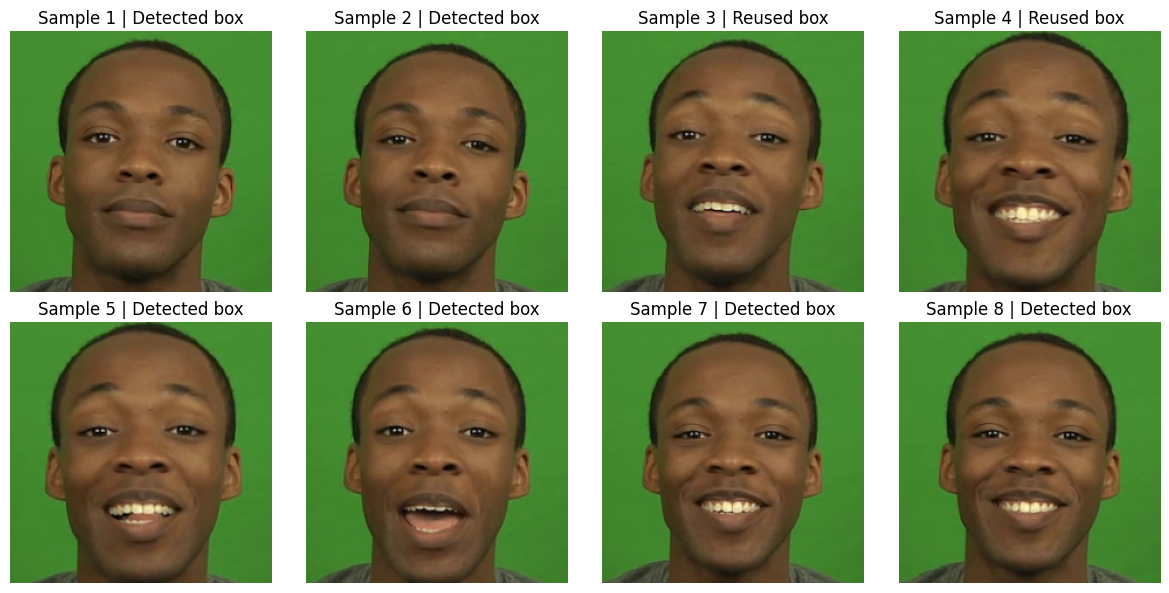

Face crops shape: (8, 224, 224, 3)
Samples using reused boxes: [3, 4]


In [ ]:
def extract_face_crops(selected_frames, output_size=224):
    boxes = []

    for frame in selected_frames:
        gray = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)
        detected = face_detector.detectMultiScale(
            gray,
            scaleFactor=1.1,
            minNeighbors=5,
            minSize=(40, 40),
        )

        box = (
            max(detected, key=lambda b: b[2] * b[3])
            if len(detected) > 0 else None
        )
        boxes.append(box)

    valid_positions = [i for i, box in enumerate(boxes) if box is not None]

    if not valid_positions:
        raise RuntimeError("No faces detected in any sampled frame.")

    crops = []
    reused_positions = []

    for i, frame in enumerate(selected_frames):
        box = boxes[i]

        if box is None:
            nearest = min(valid_positions, key=lambda j: abs(j - i))
            box = boxes[nearest]
            reused_positions.append(i)

        x, y, w, h = map(int, box)


        side = int(np.ceil(max(w, h) * 1.30))
        center_x = x + w / 2
        center_y = y + h / 2
        height, width = frame.shape[:2]

        side = min(side, height, width)
        x1 = int(np.clip(round(center_x - side / 2), 0, width - side))
        y1 = int(np.clip(round(center_y - side / 2), 0, height - side))

        crop = frame[y1:y1 + side, x1:x1 + side]
        crop = cv2.resize(crop, (output_size, output_size))
        crops.append(cv2.cvtColor(crop, cv2.COLOR_BGR2RGB))

    return np.stack(crops), reused_positions


problem_crops, reused_positions = extract_face_crops(problem_frames)

fig, axes = plt.subplots(2, 4, figsize=(12, 6))

for i, (ax, crop) in enumerate(zip(axes.flat, problem_crops)):
    ax.imshow(crop)
    source = "Reused box" if i in reused_positions else "Detected box"
    ax.set_title(f"Sample {i + 1} | {source}")
    ax.axis("off")

plt.tight_layout()
plt.show()

print(f"Face crops shape: {problem_crops.shape}")
print(f"Samples using reused boxes: {[i + 1 for i in reused_positions]}")

In [ ]:
from pathlib import Path
from tqdm.auto import tqdm
import os
CACHE_DIR = PROJECT_DIR / "face_cache_v1"
CACHE_DIR.mkdir(parents=True, exist_ok=True)

for split_name, split_df in [("train", fit_df), ("validation", val_df)]:
    split_dir = CACHE_DIR / split_name
    split_dir.mkdir(parents=True, exist_ok=True)

    split_df.to_csv(CACHE_DIR / f"{split_name}_metadata.csv", index=False)

    records = []

    for row in tqdm(
        split_df.itertuples(index=False),
        total=len(split_df),
        desc=f"Processing {split_name}",
    ):
        output_path = split_dir / f"{row.video_id}.npz"
        temporary_path = split_dir / f"{row.video_id}.tmp.npz"

        try:
            if output_path.exists():
                with np.load(output_path, allow_pickle=False) as cached:
                    crops = cached["faces"]
                    reused = cached["reused_positions"].tolist()

                    if crops.shape != (8, 224, 224, 3):
                        raise ValueError("Unexpected cached face shape.")
                    if crops.dtype != np.uint8:
                        raise ValueError("Unexpected cached face dtype.")

                status = "cached"
            else:
                selected_frames = sample_video_frames(row.video_path)
                crops, reused = extract_face_crops(selected_frames)

                np.savez_compressed(
                    temporary_path,
                    faces=crops,
                    reused_positions=np.asarray(reused, dtype=np.int64),
                )
                os.replace(temporary_path, output_path)
                status = "processed"

            records.append({
                "video_id": row.video_id,
                "Label": row.Label,
                "Speaker": row.Speaker,
                "cache_path": str(output_path),
                "reused_boxes": len(reused),
                "status": status,
                "error": "",
            })

        except Exception as exc:
            records.append({
                "video_id": row.video_id,
                "Label": row.Label,
                "Speaker": row.Speaker,
                "cache_path": str(output_path),
                "reused_boxes": None,
                "status": "error",
                "error": str(exc),
            })

        # Save progress regularly so errors remain recorded.
        if len(records) % 100 == 0:
            pd.DataFrame(records).to_csv(
                CACHE_DIR / f"{split_name}_processing_log.csv",
                index=False,
            )

    log_df = pd.DataFrame(records)
    log_df.to_csv(
        CACHE_DIR / f"{split_name}_processing_log.csv",
        index=False,
    )

    print(f"\n{split_name.capitalize()} summary:")
    print(log_df["status"].value_counts().to_string())

    errors = log_df[log_df["status"] == "error"]
    if not errors.empty:
        print("\nFirst errors:")
        print(errors[["video_id", "error"]].head(10).to_string(index=False))

print(f"\nCache directory: {CACHE_DIR}")

Processing train:   0%|          | 0/4667 [00:00<?, ?it/s]


Train summary:
status
processed    4667


Processing validation:   0%|          | 0/1223 [00:00<?, ?it/s]


Validation summary:
status
processed    1222
error           1

First errors:
       video_id                                   error
1076_MTI_SAD_XX No faces detected in any sampled frame.

Cache directory: /content/drive/MyDrive/Affective Project/face_cache_v1


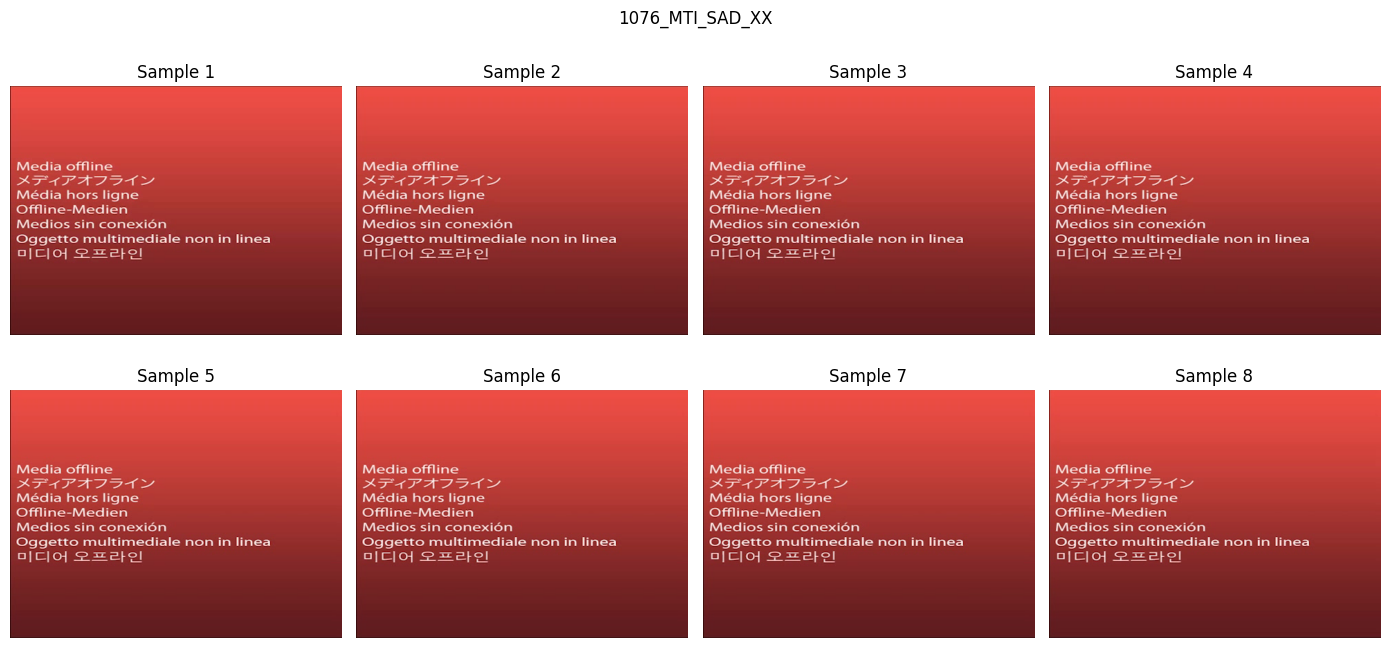

In [ ]:
failed_id = "1076_MTI_SAD_XX"
failed_row = val_df.loc[val_df["video_id"] == failed_id].iloc[0]

failed_frames = sample_video_frames(failed_row["video_path"])

fig, axes = plt.subplots(2, 4, figsize=(14, 7))

for i, (ax, frame) in enumerate(zip(axes.flat, failed_frames)):
    ax.imshow(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB))
    ax.set_title(f"Sample {i + 1}")
    ax.axis("off")

fig.suptitle(failed_id)
plt.tight_layout()
plt.show()

In [ ]:
train_log = pd.read_csv(CACHE_DIR / "train_processing_log.csv")
val_log = pd.read_csv(CACHE_DIR / "validation_processing_log.csv")

valid_statuses = ["processed", "cached"]

visual_train_df = fit_df.merge(
    train_log.loc[
        train_log["status"].isin(valid_statuses),
        ["video_id", "cache_path"],
    ],
    on="video_id",
    how="inner",
    validate="one_to_one",
)

visual_val_df = val_df.merge(
    val_log.loc[
        val_log["status"].isin(valid_statuses),
        ["video_id", "cache_path"],
    ],
    on="video_id",
    how="inner",
    validate="one_to_one",
)

excluded_df = val_log.loc[
    val_log["status"] == "error"
].copy()

excluded_df["exclusion_reason"] = excluded_df["video_id"].map({
    "1076_MTI_SAD_XX": "Media offline placeholder in sampled video frames."
}).fillna("Preprocessing failure requiring review.")

excluded_df.to_csv(CACHE_DIR / "visual_exclusions.csv", index=False)
visual_train_df.to_csv(CACHE_DIR / "visual_train.csv", index=False)
visual_val_df.to_csv(CACHE_DIR / "visual_validation.csv", index=False)

print(f"Visual training videos: {len(visual_train_df)}")
print(f"Visual validation videos: {len(visual_val_df)}")
print(f"Excluded validation videos: {len(excluded_df)}")

Visual training videos: 4667
Visual validation videos: 1222
Excluded validation videos: 1


In [ ]:
from google.colab import drive
from pathlib import Path
import pandas as pd
import torch

drive.mount("/content/drive")

PROJECT_DIR = Path("/content/drive/MyDrive/Affective Project")
VIDEO_DIR = PROJECT_DIR / "videos"
CACHE_DIR = PROJECT_DIR / "face_cache_v1"

visual_train_df = pd.read_csv(CACHE_DIR / "visual_train.csv")
visual_val_df = pd.read_csv(CACHE_DIR / "visual_validation.csv")

print(f"Training videos: {len(visual_train_df)}")
print(f"Validation videos: {len(visual_val_df)}")
print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    DEVICE = torch.device("cuda")
    print("GPU:", torch.cuda.get_device_name(0))
else:
    DEVICE = torch.device("cpu")
    print("GPU is still unavailable.")

Mounted at /content/drive
Training videos: 4667
Validation videos: 1222
PyTorch version: 2.11.0+cu130
CUDA available: True
GPU: Tesla T4


In [ ]:
import numpy as np
import random
from torch.utils.data import Dataset, DataLoader

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

CLASS_NAMES = ["Anger", "Disgust", "Fear", "Happy", "Neutral", "Sad"]
LABEL_TO_ID = {name: i for i, name in enumerate(CLASS_NAMES)}

class FaceVideoDataset(Dataset):
    def __init__(self, metadata, training=False):
        self.metadata = metadata.reset_index(drop=True).copy()
        self.training = training

        unknown = set(self.metadata["Label"]) - set(CLASS_NAMES)
        if unknown:
            raise ValueError(f"Unknown labels: {unknown}")

        self.mean = torch.tensor(
            [0.485, 0.456, 0.406], dtype=torch.float32
        ).view(1, 3, 1, 1)

        self.std = torch.tensor(
            [0.229, 0.224, 0.225], dtype=torch.float32
        ).view(1, 3, 1, 1)

    def __len__(self):
        return len(self.metadata)

    def __getitem__(self, index):
        row = self.metadata.iloc[index]

        with np.load(row["cache_path"], allow_pickle=False) as cached:
            faces = cached["faces"].copy()

        if faces.shape != (8, 224, 224, 3) or faces.dtype != np.uint8:
            raise ValueError(f"Invalid face cache: {row['video_id']}")

        images = torch.from_numpy(faces).permute(0, 3, 1, 2).float() / 255.0

        if self.training and torch.rand(()).item() < 0.5:
            images = images.flip(-1)

        images = (images - self.mean) / self.std
        label = LABEL_TO_ID[row["Label"]]

        return images, label, row["video_id"]


train_dataset = FaceVideoDataset(visual_train_df, training=True)
val_dataset = FaceVideoDataset(visual_val_df, training=False)

train_loader = DataLoader(
    train_dataset,
    batch_size=8,
    shuffle=True,
    num_workers=0,
    pin_memory=True,
    generator=torch.Generator().manual_seed(SEED),
)

val_loader = DataLoader(
    val_dataset,
    batch_size=8,
    shuffle=False,
    num_workers=0,
    pin_memory=True,
)

images, labels, video_ids = next(iter(train_loader))

print("Image batch shape:", tuple(images.shape))
print("Label batch shape:", tuple(labels.shape))
print("Labels:", labels.tolist())
print("First video ID:", video_ids[0])
print("Class mapping:", LABEL_TO_ID)

Image batch shape: (8, 8, 3, 224, 224)
Label batch shape: (8,)
Labels: [4, 2, 0, 5, 1, 2, 3, 5]
First video ID: 1059_ITH_NEU_XX
Class mapping: {'Anger': 0, 'Disgust': 1, 'Fear': 2, 'Happy': 3, 'Neutral': 4, 'Sad': 5}


In [ ]:
import torch.nn as nn
from torchvision.models import resnet18, ResNet18_Weights

class VisualEmotionModel(nn.Module):
    def __init__(self, num_classes=6):
        super().__init__()

        self.backbone = resnet18(
            weights=ResNet18_Weights.IMAGENET1K_V1
        )

        self.backbone.fc = nn.Linear(
            self.backbone.fc.in_features,
            num_classes,
        )

    def forward(self, images):
        batch_size, num_frames, channels, height, width = images.shape

        flat_images = images.reshape(
            batch_size * num_frames, channels, height, width
        )

        frame_logits = self.backbone(flat_images)
        frame_logits = frame_logits.reshape(batch_size, num_frames, -1)

        frame_log_probs = torch.log_softmax(frame_logits.float(), dim=-1)
        video_log_probs = (
            torch.logsumexp(frame_log_probs, dim=1)
            - np.log(num_frames)
        )

        return video_log_probs


model = VisualEmotionModel(num_classes=len(CLASS_NAMES)).to(DEVICE)

model.eval()

with torch.no_grad():
    video_log_probs = model(images.to(DEVICE))
    video_probs = video_log_probs.exp()

print("Output shape:", tuple(video_probs.shape))
print("Probability sums:", video_probs.sum(dim=1).cpu().tolist())
print("Trainable parameters:", sum(
    p.numel() for p in model.parameters() if p.requires_grad
))

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:01<00:00, 40.6MB/s]


Output shape: (8, 6)
Probability sums: [1.0, 0.9999998807907104, 1.0, 0.9999999403953552, 1.0, 1.0, 1.0, 1.0]
Trainable parameters: 11179590


In [ ]:
import time
from tqdm.auto import tqdm
from sklearn.metrics import accuracy_score, f1_score

RUN_DIR = PROJECT_DIR / "visual_resnet18"
RUN_DIR.mkdir(parents=True, exist_ok=True)

criterion = nn.NLLLoss()

optimizer = torch.optim.AdamW(
    [
        {
            "params": [
                p for name, p in model.backbone.named_parameters()
                if not name.startswith("fc.")
            ],
            "lr": 1e-4,
        },
        {"params": model.backbone.fc.parameters(), "lr": 1e-3},
    ],
    weight_decay=1e-4,
)

scaler = torch.amp.GradScaler("cuda")
history = []
best_val_f1 = -1.0

def run_epoch(loader, training):
    model.train(training)
    total_loss = 0.0
    all_labels = []
    all_predictions = []

    for batch_images, batch_labels, _ in tqdm(
        loader,
        desc="Training" if training else "Validation",
    ):
        batch_images = batch_images.to(DEVICE, non_blocking=True)
        batch_labels = batch_labels.to(DEVICE, non_blocking=True)

        if training:
            optimizer.zero_grad(set_to_none=True)

        with torch.set_grad_enabled(training):
            with torch.autocast(device_type="cuda", dtype=torch.float16):
                log_probs = model(batch_images)
                loss = criterion(log_probs, batch_labels)

            if training:
                scaler.scale(loss).backward()
                scaler.step(optimizer)
                scaler.update()

        total_loss += loss.item() * batch_labels.size(0)
        all_labels.extend(batch_labels.detach().cpu().tolist())
        all_predictions.extend(log_probs.argmax(dim=1).detach().cpu().tolist())

    return {
        "loss": total_loss / len(loader.dataset),
        "accuracy": accuracy_score(all_labels, all_predictions),
        "macro_f1": f1_score(
            all_labels,
            all_predictions,
            labels=list(range(len(CLASS_NAMES))),
            average="macro",
            zero_division=0,
        ),
    }


start = time.perf_counter()
train_metrics = run_epoch(train_loader, training=True)
val_metrics = run_epoch(val_loader, training=False)

epoch = 1
history.append({
    "epoch": epoch,
    **{f"train_{k}": v for k, v in train_metrics.items()},
    **{f"val_{k}": v for k, v in val_metrics.items()},
})
best_val_f1 = val_metrics["macro_f1"]

checkpoint = {
    "epoch": epoch,
    "model_state_dict": model.state_dict(),
    "optimizer_state_dict": optimizer.state_dict(),
    "scaler_state_dict": scaler.state_dict(),
    "class_names": CLASS_NAMES,
    "best_val_f1": best_val_f1,
    "history": history,
    "seed": SEED,
}

# Write each checkpoint to a temporary file before replacing it.
for filename in ["last_checkpoint.pt", "best_checkpoint.pt"]:
    temporary_path = RUN_DIR / f"{filename}.tmp"
    torch.save(checkpoint, temporary_path)
    temporary_path.replace(RUN_DIR / filename)

pd.DataFrame(history).to_csv(RUN_DIR / "history.csv", index=False)

print("\nEpoch 1 results:")
print(pd.DataFrame(history).to_string(index=False))
print(f"\nElapsed time: {(time.perf_counter() - start) / 60:.1f} minutes")
print(f"Checkpoints saved to: {RUN_DIR}")

Training:   0%|          | 0/584 [00:00<?, ?it/s]

Validation:   0%|          | 0/153 [00:00<?, ?it/s]


Epoch 1 results:
 epoch  train_loss  train_accuracy  train_macro_f1  val_loss  val_accuracy  val_macro_f1
     1    1.162218        0.568674         0.56302  1.518068      0.494272      0.435629

Elapsed time: 91.0 minutes
Checkpoints saved to: /content/drive/MyDrive/Affective Project/visual_resnet18


In [ ]:
import shutil
import time
from pathlib import Path
from tqdm.auto import tqdm

LOCAL_CACHE_DIR = Path("/content/face_cache_v1")
start = time.perf_counter()

for split_name, metadata in [
    ("train", visual_train_df),
    ("validation", visual_val_df),
]:
    destination_dir = LOCAL_CACHE_DIR / split_name
    destination_dir.mkdir(parents=True, exist_ok=True)

    local_paths = []

    for row in tqdm(
        metadata.itertuples(index=False),
        total=len(metadata),
        desc=f"Copying {split_name} cache",
    ):
        source = Path(row.cache_path)
        destination = destination_dir / source.name

        if (
            not destination.exists()
            or destination.stat().st_size != source.stat().st_size
        ):
            temporary = destination.with_suffix(".tmp")
            shutil.copy2(source, temporary)
            temporary.replace(destination)

        local_paths.append(str(destination))

    metadata["cache_path"] = local_paths

print(f"\nCopy time: {(time.perf_counter() - start) / 60:.1f} minutes")
print("Local cache:", LOCAL_CACHE_DIR)
print("Model checkpoints remain saved in Google Drive.")

Copying train cache:   0%|          | 0/4667 [00:00<?, ?it/s]

Copying validation cache:   0%|          | 0/1222 [00:00<?, ?it/s]


Copy time: 1.1 minutes
Local cache: /content/face_cache_v1
Model checkpoints remain saved in Google Drive.


In [ ]:
train_dataset = FaceVideoDataset(visual_train_df, training=True)
val_dataset = FaceVideoDataset(visual_val_df, training=False)

train_loader = DataLoader(
    train_dataset,
    batch_size=8,
    shuffle=True,
    num_workers=2,
    pin_memory=True,
    persistent_workers=True,
    generator=torch.Generator().manual_seed(SEED),
)

val_loader = DataLoader(
    val_dataset,
    batch_size=8,
    shuffle=False,
    num_workers=2,
    pin_memory=True,
    persistent_workers=True,
)

start = time.perf_counter()
iterator = iter(train_loader)

for _ in range(20):
    batch_images, batch_labels, _ = next(iterator)

elapsed = time.perf_counter() - start

print("Image batch shape:", tuple(batch_images.shape))
print(f"Loading 20 batches: {elapsed:.2f} seconds")
print(f"Average loading time per batch: {elapsed / 20:.2f} seconds")
print("First cache path:", train_dataset.metadata.iloc[0]["cache_path"])

Image batch shape: (8, 8, 3, 224, 224)
Loading 20 batches: 7.22 seconds
Average loading time per batch: 0.36 seconds
First cache path: /content/face_cache_v1/train/1001_DFA_ANG_XX.npz


In [ ]:
# Resume from the saved checkpoint.
checkpoint = torch.load(
    RUN_DIR / "last_checkpoint.pt",
    map_location=DEVICE,
    weights_only=True,
)

assert checkpoint["class_names"] == CLASS_NAMES, "Class order mismatch."

model.load_state_dict(checkpoint["model_state_dict"])
optimizer.load_state_dict(checkpoint["optimizer_state_dict"])
scaler.load_state_dict(checkpoint["scaler_state_dict"])

history = checkpoint["history"]
best_val_f1 = checkpoint["best_val_f1"]
start_epoch = checkpoint["epoch"] + 1

MAX_EPOCHS = 10
PATIENCE = 3

best_epoch = max(history, key=lambda row: row["val_macro_f1"])["epoch"]
epochs_without_improvement = checkpoint["epoch"] - best_epoch

def save_checkpoint(filename, state):
    temporary_path = RUN_DIR / f"{filename}.tmp"
    torch.save(state, temporary_path)
    temporary_path.replace(RUN_DIR / filename)

for epoch in range(start_epoch, MAX_EPOCHS + 1):
    start = time.perf_counter()

    train_metrics = run_epoch(train_loader, training=True)
    val_metrics = run_epoch(val_loader, training=False)

    improved = val_metrics["macro_f1"] > best_val_f1

    if improved:
        best_val_f1 = val_metrics["macro_f1"]
        epochs_without_improvement = 0
    else:
        epochs_without_improvement += 1

    history.append({
        "epoch": epoch,
        **{f"train_{k}": v for k, v in train_metrics.items()},
        **{f"val_{k}": v for k, v in val_metrics.items()},
    })

    state = {
        "epoch": epoch,
        "model_state_dict": model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "scaler_state_dict": scaler.state_dict(),
        "class_names": CLASS_NAMES,
        "best_val_f1": best_val_f1,
        "history": history,
        "seed": SEED,
    }

    save_checkpoint("last_checkpoint.pt", state)

    if improved:
        save_checkpoint("best_checkpoint.pt", state)

    pd.DataFrame(history).to_csv(RUN_DIR / "history.csv", index=False)

    print(f"\nEpoch {epoch} results:")
    print(pd.DataFrame([history[-1]]).to_string(index=False))
    print(f"Elapsed time: {(time.perf_counter() - start) / 60:.1f} minutes")
    print(f"Best validation Macro-F1: {best_val_f1:.4f}")
    print(f"Epochs without improvement: {epochs_without_improvement}")

    if epochs_without_improvement >= PATIENCE:
        print("\nEarly stopping triggered.")
        break

print("\nTraining history:")
print(pd.DataFrame(history).to_string(index=False))

Training:   0%|          | 0/584 [00:00<?, ?it/s]

Validation:   0%|          | 0/153 [00:00<?, ?it/s]


Epoch 2 results:
 epoch  train_loss  train_accuracy  train_macro_f1  val_loss  val_accuracy  val_macro_f1
     2    0.877696         0.68588        0.682791  1.371643        0.5982      0.586437
Elapsed time: 2.8 minutes
Best validation Macro-F1: 0.5864
Epochs without improvement: 0


Training:   0%|          | 0/584 [00:00<?, ?it/s]

Validation:   0%|          | 0/153 [00:00<?, ?it/s]


Epoch 3 results:
 epoch  train_loss  train_accuracy  train_macro_f1  val_loss  val_accuracy  val_macro_f1
     3    0.753863        0.741161        0.739596  1.414092      0.594108       0.60019
Elapsed time: 2.8 minutes
Best validation Macro-F1: 0.6002
Epochs without improvement: 0


... (5 outputs left out)


Epoch 5 results:
 epoch  train_loss  train_accuracy  train_macro_f1  val_loss  val_accuracy  val_macro_f1
     5    0.648258        0.796657        0.794717  1.564276      0.592471      0.565972
Elapsed time: 2.6 minutes
Best validation Macro-F1: 0.6002
Epochs without improvement: 2


Training:   0%|          | 0/584 [00:00<?, ?it/s]

Validation:   0%|          | 0/153 [00:00<?, ?it/s]


Epoch 6 results:
 epoch  train_loss  train_accuracy  train_macro_f1  val_loss  val_accuracy  val_macro_f1
     6    0.593748        0.809299        0.807639  1.922243      0.551555      0.539891
Elapsed time: 2.5 minutes
Best validation Macro-F1: 0.6002
Epochs without improvement: 3

Early stopping triggered.

Training history:
 epoch  train_loss  train_accuracy  train_macro_f1  val_loss  val_accuracy  val_macro_f1
     1    1.162218        0.568674        0.563020  1.518068      0.494272      0.435629
     2    0.877696        0.685880        0.682791  1.371643      0.598200      0.586437
     3    0.753863        0.741161        0.739596  1.414092      0.594108      0.600190
     4    0.703699        0.767302        0.766076  1.705208      0.578560      0.542224
     5    0.648258        0.796657        0.794717  1.564276      0.592471      0.565972
     6    0.593748        0.809299        0.807639  1.922243      0.551555      0.539891


In [ ]:
baseline_dir = PROJECT_DIR / "visual_resnet18"
RUN_DIR = PROJECT_DIR / "visual_resnet18_low_lr"
RUN_DIR.mkdir(parents=True, exist_ok=True)

baseline = torch.load(
    baseline_dir / "best_checkpoint.pt",
    map_location=DEVICE,
    weights_only=True,
)

assert baseline["class_names"] == CLASS_NAMES, "Class order mismatch."
model.load_state_dict(baseline["model_state_dict"])

optimizer = torch.optim.AdamW(
    [
        {
            "params": [
                p for name, p in model.backbone.named_parameters()
                if not name.startswith("fc.")
            ],
            "lr": 1e-5,
        },
        {"params": model.backbone.fc.parameters(), "lr": 1e-4},
    ],
    weight_decay=1e-4,
)

scaler = torch.amp.GradScaler("cuda")

best_val_f1 = baseline["best_val_f1"]
history = []
epochs_without_improvement = 0

save_checkpoint("best_checkpoint.pt", {
    "epoch": 0,
    "model_state_dict": model.state_dict(),
    "class_names": CLASS_NAMES,
    "best_val_f1": best_val_f1,
    "source_baseline_epoch": baseline["epoch"],
    "history": history,
    "seed": SEED,
})

for epoch in range(1, 7):
    start = time.perf_counter()

    train_metrics = run_epoch(train_loader, training=True)
    val_metrics = run_epoch(val_loader, training=False)

    improved = val_metrics["macro_f1"] > best_val_f1
    epochs_without_improvement = (
        0 if improved else epochs_without_improvement + 1
    )

    if improved:
        best_val_f1 = val_metrics["macro_f1"]

    history.append({
        "epoch": epoch,
        **{f"train_{k}": v for k, v in train_metrics.items()},
        **{f"val_{k}": v for k, v in val_metrics.items()},
    })

    state = {
        "epoch": epoch,
        "model_state_dict": model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "scaler_state_dict": scaler.state_dict(),
        "class_names": CLASS_NAMES,
        "best_val_f1": best_val_f1,
        "source_baseline_epoch": baseline["epoch"],
        "history": history,
        "seed": SEED,
    }

    save_checkpoint("last_checkpoint.pt", state)
    if improved:
        save_checkpoint("best_checkpoint.pt", state)

    pd.DataFrame(history).to_csv(RUN_DIR / "history.csv", index=False)

    print(f"\nFine-tuning epoch {epoch}:")
    print(pd.DataFrame([history[-1]]).to_string(index=False))
    print(f"Elapsed time: {(time.perf_counter() - start) / 60:.1f} minutes")
    print(f"Best validation Macro-F1: {best_val_f1:.4f}")

    if epochs_without_improvement >= 3:
        print("Early stopping triggered.")
        break

print("\nFine-tuning history:")
print(pd.DataFrame(history).to_string(index=False))

Training:   0%|          | 0/584 [00:00<?, ?it/s]

Validation:   0%|          | 0/153 [00:00<?, ?it/s]


Fine-tuning epoch 1:
 epoch  train_loss  train_accuracy  train_macro_f1  val_loss  val_accuracy  val_macro_f1
     1    0.559524        0.841654        0.840987  1.300173      0.635843      0.637199
Elapsed time: 2.8 minutes
Best validation Macro-F1: 0.6372


Training:   0%|          | 0/584 [00:00<?, ?it/s]

Validation:   0%|          | 0/153 [00:00<?, ?it/s]


Fine-tuning epoch 2:
 epoch  train_loss  train_accuracy  train_macro_f1  val_loss  val_accuracy  val_macro_f1
     2    0.510347        0.866081        0.865138  1.318804       0.62766      0.630867
Elapsed time: 2.6 minutes
Best validation Macro-F1: 0.6372


... (8 outputs left out)


Fine-tuning epoch 5:
 epoch  train_loss  train_accuracy  train_macro_f1  val_loss  val_accuracy  val_macro_f1
     5     0.43825         0.89565        0.895059  1.409472      0.624386      0.622323
Elapsed time: 2.6 minutes
Best validation Macro-F1: 0.6469


Training:   0%|          | 0/584 [00:00<?, ?it/s]

Validation:   0%|          | 0/153 [00:00<?, ?it/s]


Fine-tuning epoch 6:
 epoch  train_loss  train_accuracy  train_macro_f1  val_loss  val_accuracy  val_macro_f1
     6    0.416964        0.908721        0.908556  1.452913      0.603928       0.59953
Elapsed time: 2.6 minutes
Best validation Macro-F1: 0.6469

Fine-tuning history:
 epoch  train_loss  train_accuracy  train_macro_f1  val_loss  val_accuracy  val_macro_f1
     1    0.559524        0.841654        0.840987  1.300173      0.635843      0.637199
     2    0.510347        0.866081        0.865138  1.318804      0.627660      0.630867
     3    0.478019        0.878937        0.878377  1.318294      0.626841      0.622948
     4    0.448290        0.888579        0.888135  1.328988      0.645663      0.646919
     5    0.438250        0.895650        0.895059  1.409472      0.624386      0.622323
     6    0.416964        0.908721        0.908556  1.452913      0.603928      0.599530


Evaluating best model:   0%|          | 0/153 [00:00<?, ?it/s]


Selected epoch: 4
Validation accuracy: 0.6457
Validation Macro-F1: 0.6469

Classification report:
              precision    recall  f1-score   support

       Anger      0.479     0.598     0.532       209
     Disgust      0.854     0.866     0.860       209
        Fear      0.627     0.531     0.575       209
       Happy      0.908     0.895     0.901       209
     Neutral      0.692     0.517     0.592       178
         Sad      0.399     0.447     0.422       208

    accuracy                          0.646      1222
   macro avg      0.660     0.642     0.647      1222
weighted avg      0.659     0.646     0.649      1222



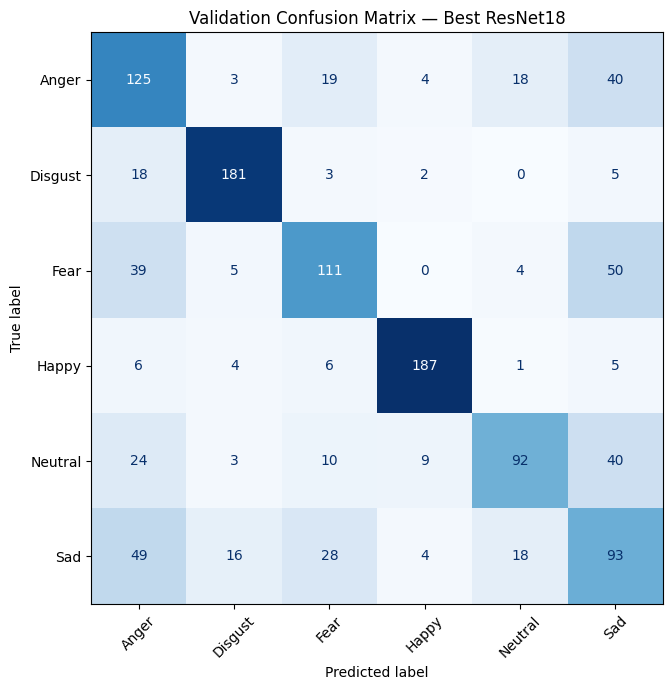

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.metrics import ConfusionMatrixDisplay

best_checkpoint = torch.load(
    RUN_DIR / "best_checkpoint.pt",
    map_location=DEVICE,
    weights_only=True,
)

assert best_checkpoint["class_names"] == CLASS_NAMES, "Class order mismatch."

model.load_state_dict(best_checkpoint["model_state_dict"])
model.eval()

records = []

with torch.inference_mode():
    for batch_images, batch_labels, video_ids in tqdm(
        val_loader,
        desc="Evaluating best model",
    ):
        batch_images = batch_images.to(DEVICE, non_blocking=True)

        with torch.autocast(device_type="cuda", dtype=torch.float16):
            probabilities = model(batch_images).exp()

        probabilities = probabilities.cpu().numpy()
        labels = batch_labels.numpy()

        for video_id, true_id, probs in zip(
            video_ids, labels, probabilities
        ):
            predicted_id = int(probs.argmax())

            records.append({
                "video_id": video_id,
                "true_label": CLASS_NAMES[int(true_id)],
                "predicted_label": CLASS_NAMES[predicted_id],
                "confidence": float(probs[predicted_id]),
                **{
                    f"prob_{name}": float(probs[i])
                    for i, name in enumerate(CLASS_NAMES)
                },
            })

val_predictions = pd.DataFrame(records).merge(
    visual_val_df[["video_id", "Speaker"]],
    on="video_id",
    validate="one_to_one",
)

val_predictions.to_csv(
    RUN_DIR / "validation_predictions.csv",
    index=False,
)

y_true = val_predictions["true_label"]
y_pred = val_predictions["predicted_label"]

print(f"\nSelected epoch: {best_checkpoint['epoch']}")
print(f"Validation accuracy: {accuracy_score(y_true, y_pred):.4f}")
print(
    "Validation Macro-F1:",
    f"{f1_score(y_true, y_pred, labels=CLASS_NAMES, average='macro', zero_division=0):.4f}",
)

print("\nClassification report:")
print(classification_report(
    y_true,
    y_pred,
    labels=CLASS_NAMES,
    target_names=CLASS_NAMES,
    digits=3,
    zero_division=0,
))

report = classification_report(
    y_true,
    y_pred,
    labels=CLASS_NAMES,
    target_names=CLASS_NAMES,
    output_dict=True,
    zero_division=0,
)
pd.DataFrame(report).T.to_csv(RUN_DIR / "validation_report.csv")

cm = confusion_matrix(y_true, y_pred, labels=CLASS_NAMES)

fig, ax = plt.subplots(figsize=(8, 7))
ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=CLASS_NAMES,
).plot(ax=ax, cmap="Blues", colorbar=False)

ax.set_title("Validation Confusion Matrix — Best ResNet18")
plt.xticks(rotation=45)
plt.tight_layout()
fig.savefig(
    RUN_DIR / "validation_confusion_matrix.png",
    dpi=150,
    bbox_inches="tight",
)
plt.show()

In [ ]:
import json

SELECTED_MODEL_DIR = PROJECT_DIR / "visual_resnet18_low_lr"
FINAL_DIR = PROJECT_DIR / "visual_final"
FINAL_DIR.mkdir(parents=True, exist_ok=True)

selected_checkpoint = torch.load(
    SELECTED_MODEL_DIR / "best_checkpoint.pt",
    map_location="cpu",
    weights_only=True,
)

assert selected_checkpoint["class_names"] == CLASS_NAMES, \
    "Class order mismatch."
assert selected_checkpoint["epoch"] == 4, \
    "Unexpected selected checkpoint."

final_weights = {
    "model_state_dict": selected_checkpoint["model_state_dict"],
    "class_names": CLASS_NAMES,
}

temporary_path = FINAL_DIR / "resnet18_visual.pt.tmp"
torch.save(final_weights, temporary_path)
temporary_path.replace(FINAL_DIR / "resnet18_visual.pt")

config = {
    "architecture": "ResNet18",
    "pretraining": "ImageNet-1K",
    "selected_experiment": "low_learning_rate",
    "selected_fine_tuning_epoch": 4,
    "selection_metric": "validation_macro_f1",
    "validation_macro_f1": float(selected_checkpoint["best_val_f1"]),
    "class_names": CLASS_NAMES,
    "num_frames": 8,
    "frame_sampling": "uniform_including_endpoints",
    "image_size": [224, 224],
    "color_space": "RGB",
    "normalization_mean": [0.485, 0.456, 0.406],
    "normalization_std": [0.229, 0.224, 0.225],
    "aggregation": "mean_frame_probabilities",
    "face_detector": "OpenCV Haar frontal face",
    "face_scale_factor": 1.1,
    "face_min_neighbors": 5,
    "face_min_size": [40, 40],
    "crop_side_multiplier": 1.30,
    "missing_face_policy": "reuse_nearest_detected_box_within_video",
    "no_detected_faces_policy": "flag_for_review",
    "seed": SEED,
}

with open(FINAL_DIR / "config.json", "w") as file:
    json.dump(config, file, indent=2)

model.load_state_dict(selected_checkpoint["model_state_dict"])
model.to(DEVICE)
model.eval()

print("Final model saved:", FINAL_DIR / "resnet18_visual.pt")
print("Configuration saved:", FINAL_DIR / "config.json")
print("Selected fine-tuning epoch:", selected_checkpoint["epoch"])
print(f"Validation Macro-F1: {config['validation_macro_f1']:.4f}")

Final model saved: /content/drive/MyDrive/Affective Project/visual_final/resnet18_visual.pt
Configuration saved: /content/drive/MyDrive/Affective Project/visual_final/config.json
Selected fine-tuning epoch: 4
Validation Macro-F1: 0.6469


In [ ]:
test_df = pd.read_csv(PROJECT_DIR / "test.csv")

emotion_codes = {
    "Anger": "ANG",
    "Disgust": "DIS",
    "Fear": "FEA",
    "Happy": "HAP",
    "Neutral": "NEU",
    "Sad": "SAD",
}

intensity_codes = {
    "Unspecified": "XX",
    "High": "HI",
    "Low": "LO",
    "Medium": "MD",
}

for column in ["Convention", "Label", "Intesnsity"]:
    test_df[column] = test_df[column].astype(str).str.strip()

emotions = test_df["Label"].map(emotion_codes)
intensities = test_df["Intesnsity"].map(intensity_codes)

assert emotions.notna().all(), "Unknown emotion labels."
assert intensities.notna().all(), "Unknown intensity labels."

test_df["video_id"] = (
    test_df["Speaker"].astype(int).astype(str)
    + "_" + test_df["Convention"]
    + "_" + emotions
    + "_" + intensities
)

test_df["video_path"] = test_df["video_id"].apply(
    lambda video_id: str(VIDEO_DIR / f"{video_id}.flv")
)

assert test_df["video_id"].is_unique, "Duplicate test video IDs."
assert set(test_df["Speaker"]).isdisjoint(visual_train_df["Speaker"]), \
    "Train/test speaker overlap."
assert set(test_df["Speaker"]).isdisjoint(visual_val_df["Speaker"]), \
    "Validation/test speaker overlap."

available_files = {
    path.name for path in VIDEO_DIR.iterdir() if path.is_file()
}

missing = test_df[
    ~test_df["video_id"].add(".flv").isin(available_files)
]

print(f"Test videos: {len(test_df)}")
print(f"Test speakers: {test_df['Speaker'].nunique()}")
print(f"Missing videos: {len(missing)}")

assert missing.empty, "Some test video files are missing."

test_df.to_csv(FINAL_DIR / "test_metadata.csv", index=False)
print("Test metadata saved.")

Test videos: 1552
Test speakers: 19
Missing videos: 0
Test metadata saved.


In [ ]:
import os
import numpy as np
from tqdm.auto import tqdm

assert callable(globals().get("sample_video_frames")), \
    "Run the cell defining sample_video_frames first."
assert callable(globals().get("extract_face_crops")), \
    "Run the cell defining extract_face_crops first."

TEST_CACHE_DIR = CACHE_DIR / "test"
TEST_CACHE_DIR.mkdir(parents=True, exist_ok=True)

test_records = []

for row in tqdm(
    test_df.itertuples(index=False),
    total=len(test_df),
    desc="Processing test",
):
    output_path = TEST_CACHE_DIR / f"{row.video_id}.npz"
    temporary_path = TEST_CACHE_DIR / f"{row.video_id}.tmp.npz"

    try:
        if output_path.exists():
            with np.load(output_path, allow_pickle=False) as cached:
                faces = cached["faces"]
                reused = cached["reused_positions"].tolist()

                if faces.shape != (8, 224, 224, 3):
                    raise ValueError("Unexpected cached face shape.")
                if faces.dtype != np.uint8:
                    raise ValueError("Unexpected cached face dtype.")

            status = "cached"
        else:
            frames = sample_video_frames(row.video_path, num_frames=8)
            faces, reused = extract_face_crops(frames)

            np.savez_compressed(
                temporary_path,
                faces=faces,
                reused_positions=np.asarray(reused, dtype=np.int64),
            )
            os.replace(temporary_path, output_path)
            status = "processed"

        test_records.append({
            "video_id": row.video_id,
            "Speaker": row.Speaker,
            "Label": row.Label,
            "cache_path": str(output_path),
            "reused_boxes": len(reused),
            "status": status,
            "error": "",
        })

    except Exception as exc:
        test_records.append({
            "video_id": row.video_id,
            "Speaker": row.Speaker,
            "Label": row.Label,
            "cache_path": str(output_path),
            "reused_boxes": None,
            "status": "error",
            "error": str(exc),
        })

    if len(test_records) % 100 == 0:
        pd.DataFrame(test_records).to_csv(
            CACHE_DIR / "test_processing_log.csv", index=False
        )

test_log = pd.DataFrame(test_records)
test_log.to_csv(CACHE_DIR / "test_processing_log.csv", index=False)

print("\nTest processing summary:")
print(test_log["status"].value_counts().to_string())

errors = test_log[test_log["status"] == "error"]
if not errors.empty:
    print("\nVideos requiring review:")
    print(errors[["video_id", "error"]].to_string(index=False))

Processing test:   0%|          | 0/1552 [00:00<?, ?it/s]


Test processing summary:
status
processed    1552


Copying test cache:   0%|          | 0/1552 [00:00<?, ?it/s]

Evaluating test:   0%|          | 0/194 [00:00<?, ?it/s]


Test accuracy: 0.6804
Test Macro-F1: 0.6733

Classification report:
              precision    recall  f1-score   support

       Anger      0.703     0.634     0.667       265
     Disgust      0.768     0.823     0.794       265
        Fear      0.579     0.660     0.617       265
       Happy      0.955     0.958     0.957       265
     Neutral      0.539     0.639     0.585       227
         Sad      0.500     0.362     0.420       265

    accuracy                          0.680      1552
   macro avg      0.674     0.679     0.673      1552
weighted avg      0.677     0.680     0.675      1552



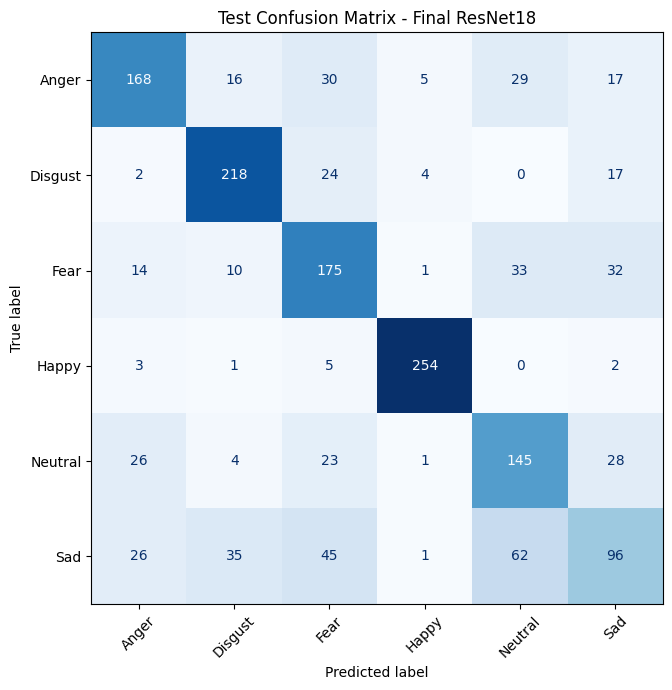

Test results saved to: /content/drive/MyDrive/Affective Project/visual_final


In [ ]:
import shutil
from pathlib import Path
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

test_log = pd.read_csv(CACHE_DIR / "test_processing_log.csv")

assert test_log["video_id"].is_unique, "Duplicate test log entries."
assert test_log["status"].isin(["processed", "cached"]).all(), \
    "Some test videos require review."

visual_test_df = test_df.merge(
    test_log[["video_id", "cache_path"]],
    on="video_id",
    how="inner",
    validate="one_to_one",
)

assert len(visual_test_df) == len(test_df), "Test samples are missing."

local_test_dir = Path("/content/face_cache_v1/test")
local_test_dir.mkdir(parents=True, exist_ok=True)
local_paths = []

for row in tqdm(
    visual_test_df.itertuples(index=False),
    total=len(visual_test_df),
    desc="Copying test cache",
):
    source = Path(row.cache_path)
    destination = local_test_dir / source.name

    if (
        not destination.exists()
        or destination.stat().st_size != source.stat().st_size
    ):
        temporary = destination.with_suffix(".tmp")
        shutil.copy2(source, temporary)
        temporary.replace(destination)

    local_paths.append(str(destination))

visual_test_df["cache_path"] = local_paths

test_dataset = FaceVideoDataset(visual_test_df, training=False)
test_loader = DataLoader(
    test_dataset,
    batch_size=8,
    shuffle=False,
    num_workers=2,
    pin_memory=True,
    persistent_workers=True,
)

final_weights = torch.load(
    FINAL_DIR / "resnet18_visual.pt",
    map_location=DEVICE,
    weights_only=True,
)

assert final_weights["class_names"] == CLASS_NAMES, "Class order mismatch."
model.load_state_dict(final_weights["model_state_dict"])
model.to(DEVICE)
model.eval()

records = []

with torch.inference_mode():
    for batch_images, batch_labels, video_ids in tqdm(
        test_loader, desc="Evaluating test"
    ):
        batch_images = batch_images.to(DEVICE, non_blocking=True)

        with torch.autocast(device_type="cuda", dtype=torch.float16):
            probabilities = model(batch_images).exp()

        probabilities = probabilities.cpu().numpy()

        for video_id, true_id, probs in zip(
            video_ids, batch_labels.tolist(), probabilities
        ):
            predicted_id = int(probs.argmax())
            records.append({
                "video_id": video_id,
                "true_label": CLASS_NAMES[true_id],
                "predicted_label": CLASS_NAMES[predicted_id],
                "confidence": float(probs[predicted_id]),
                **{
                    f"prob_{name}": float(probs[i])
                    for i, name in enumerate(CLASS_NAMES)
                },
            })

test_predictions = pd.DataFrame(records).merge(
    test_df[["video_id", "Speaker"]],
    on="video_id",
    validate="one_to_one",
)

assert len(test_predictions) == len(test_df), "Prediction count mismatch."

test_predictions.to_csv(
    FINAL_DIR / "test_predictions.csv", index=False
)

y_true = test_predictions["true_label"]
y_pred = test_predictions["predicted_label"]

metrics = {
    "num_test_videos": len(test_predictions),
    "accuracy": float(accuracy_score(y_true, y_pred)),
    "macro_f1": float(f1_score(
        y_true, y_pred,
        labels=CLASS_NAMES,
        average="macro",
        zero_division=0,
    )),
}

with open(FINAL_DIR / "test_metrics.json", "w") as file:
    json.dump(metrics, file, indent=2)

print(f"\nTest accuracy: {metrics['accuracy']:.4f}")
print(f"Test Macro-F1: {metrics['macro_f1']:.4f}")
print("\nClassification report:")
print(classification_report(
    y_true, y_pred,
    labels=CLASS_NAMES,
    digits=3,
    zero_division=0,
))

report = classification_report(
    y_true, y_pred,
    labels=CLASS_NAMES,
    output_dict=True,
    zero_division=0,
)
pd.DataFrame(report).T.to_csv(FINAL_DIR / "test_report.csv")

cm = confusion_matrix(y_true, y_pred, labels=CLASS_NAMES)
pd.DataFrame(
    cm, index=CLASS_NAMES, columns=CLASS_NAMES
).to_csv(FINAL_DIR / "test_confusion_matrix.csv")

fig, ax = plt.subplots(figsize=(8, 7))
ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=CLASS_NAMES,
).plot(ax=ax, cmap="Blues", colorbar=False)

ax.set_title("Test Confusion Matrix - Final ResNet18")
plt.xticks(rotation=45)
plt.tight_layout()
fig.savefig(
    FINAL_DIR / "test_confusion_matrix.png",
    dpi=150,
    bbox_inches="tight",
)
plt.show()

print("Test results saved to:", FINAL_DIR)

In [ ]:
from google.colab import drive
from pathlib import Path
import pandas as pd

drive.mount("/content/drive")

PROJECT_DIR = Path("/content/drive/MyDrive/Affective Project")
CACHE_DIR = PROJECT_DIR / "face_cache_v1"
FINAL_DIR = PROJECT_DIR / "visual_final"

assert PROJECT_DIR.is_dir(), f"Project folder not found: {PROJECT_DIR}"
assert (FINAL_DIR / "resnet18_visual.pt").is_file(), "Final model not found."

print("Google Drive connected.")
print("Final model found.")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Google Drive connected.
Final model found.


In [ ]:
metadata = pd.read_csv(FINAL_DIR / "test_metadata.csv")
assert metadata["video_id"].is_unique, "Duplicate video IDs."

expected_ids = set(metadata["video_id"].astype(str))

found_paths = {}
for path in CACHE_DIR.rglob("*.npz"):
    if path.stem in expected_ids:
        found_paths.setdefault(path.stem, []).append(path)

missing_ids = sorted(expected_ids - set(found_paths))
duplicate_ids = sorted(
    video_id
    for video_id, paths in found_paths.items()
    if len(paths) > 1
)

print(f"Expected test videos: {len(expected_ids)}")
print(f"Found test caches: {len(found_paths)}")
print(f"Missing test caches: {len(missing_ids)}")
print(f"Video IDs with multiple cache files: {len(duplicate_ids)}")

print("\nExample cache paths:")
for video_id in sorted(found_paths)[:5]:
    print(video_id, "->", found_paths[video_id][0])

print("\nFirst missing video IDs:")
for video_id in missing_ids[:10]:
    print(video_id)

Expected test videos: 1552
Found test caches: 787
Missing test caches: 765
Video IDs with multiple cache files: 0

Example cache paths:
1005_DFA_ANG_XX -> /content/drive/MyDrive/Affective Project/face_cache_v1/test/1005_DFA_ANG_XX.npz
1005_DFA_DIS_XX -> /content/drive/MyDrive/Affective Project/face_cache_v1/test/1005_DFA_DIS_XX.npz
1005_DFA_FEA_XX -> /content/drive/MyDrive/Affective Project/face_cache_v1/test/1005_DFA_FEA_XX.npz
1005_DFA_HAP_XX -> /content/drive/MyDrive/Affective Project/face_cache_v1/test/1005_DFA_HAP_XX.npz
1005_DFA_NEU_XX -> /content/drive/MyDrive/Affective Project/face_cache_v1/test/1005_DFA_NEU_XX.npz

First missing video IDs:
1037_MTI_HAP_XX
1037_MTI_NEU_XX
1037_MTI_SAD_XX
1037_TAI_ANG_XX
1037_TAI_DIS_XX
1037_TAI_FEA_XX
1037_TAI_HAP_XX
1037_TAI_NEU_XX
1037_TAI_SAD_XX
1037_TIE_ANG_XX


In [ ]:
import cv2
import numpy as np

face_detector = cv2.CascadeClassifier(
    cv2.data.haarcascades + "haarcascade_frontalface_default.xml"
)
assert not face_detector.empty(), "Failed to load the face detector."


def sample_video_frames(video_path, num_frames=8):
    capture = cv2.VideoCapture(str(video_path))

    if not capture.isOpened():
        capture.release()
        raise RuntimeError(f"Could not open video: {video_path}")

    frames = []

    try:
        while True:
            success, frame = capture.read()
            if not success:
                break
            frames.append(frame)
    finally:
        capture.release()

    if not frames:
        raise RuntimeError(f"No frames decoded: {video_path}")

    indices = np.linspace(
        0, len(frames) - 1, num_frames, dtype=int
    )

    return [frames[index] for index in indices]


def extract_face_crops(selected_frames, output_size=224):
    boxes = []

    for frame in selected_frames:
        gray = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)

        detections = face_detector.detectMultiScale(
            gray,
            scaleFactor=1.1,
            minNeighbors=5,
            minSize=(40, 40),
        )

        if len(detections):
            box = max(detections, key=lambda b: int(b[2]) * int(b[3]))
            boxes.append(tuple(int(value) for value in box))
        else:
            boxes.append(None)

    valid_positions = [
        index for index, box in enumerate(boxes)
        if box is not None
    ]

    if not valid_positions:
        raise RuntimeError("No faces detected in any sampled frame.")

    crops = []
    reused_positions = []

    for index, frame in enumerate(selected_frames):
        box = boxes[index]

        if box is None:
            nearest = min(
                valid_positions,
                key=lambda position: abs(position - index),
            )
            box = boxes[nearest]
            reused_positions.append(index)

        x, y, width, height = box
        frame_height, frame_width = frame.shape[:2]

        center_x = x + width / 2
        center_y = y + height / 2

        side = int(np.ceil(max(width, height) * 1.30))
        side = min(side, frame_height, frame_width)

        left = int(np.clip(
            round(center_x - side / 2), 0, frame_width - side
        ))
        top = int(np.clip(
            round(center_y - side / 2), 0, frame_height - side
        ))

        crop = frame[top:top + side, left:left + side]
        crop = cv2.resize(crop, (output_size, output_size))
        crop = cv2.cvtColor(crop, cv2.COLOR_BGR2RGB)

        crops.append(crop)

    return np.stack(crops).astype(np.uint8), reused_positions


print("Frame sampling and face cropping functions are ready.")

Frame sampling and face cropping functions are ready.


In [ ]:
from pathlib import Path
from tqdm.auto import tqdm
import pandas as pd

TEST_CACHE_DIR = CACHE_DIR / "test"
TEST_CACHE_DIR.mkdir(parents=True, exist_ok=True)

metadata = pd.read_csv(FINAL_DIR / "test_metadata.csv")
assert metadata["video_id"].is_unique, "Duplicate video IDs."

pending = metadata.loc[
    ~metadata["video_id"].map(
        lambda video_id: (TEST_CACHE_DIR / f"{video_id}.npz").is_file()
    )
].copy()

# Resolve video paths from the project folder.
pending["source_path"] = pending["video_id"].map(
    lambda video_id: PROJECT_DIR / "videos" / f"{video_id}.flv"
)

missing_sources = [
    str(path) for path in pending["source_path"]
    if not path.is_file()
]
assert not missing_sources, (
    f"Missing source videos: {len(missing_sources)}. "
    f"Examples: {missing_sources[:5]}"
)

print(f"Videos requiring cache recovery: {len(pending)}")

recovery_log = []

for row in tqdm(
    pending.itertuples(index=False),
    total=len(pending),
    desc="Recovering test caches",
):
    cache_path = TEST_CACHE_DIR / f"{row.video_id}.npz"
    temporary_path = TEST_CACHE_DIR / f"{row.video_id}.tmp.npz"

    try:
        frames = sample_video_frames(row.source_path, num_frames=8)
        faces, reused_positions = extract_face_crops(frames)

        assert faces.shape == (8, 224, 224, 3), (
            f"Unexpected face array shape: {faces.shape}"
        )

        np.savez_compressed(
            temporary_path,
            faces=faces,
            reused_positions=np.asarray(reused_positions, dtype=np.int64),
        )
        temporary_path.replace(cache_path)

        recovery_log.append({
            "video_id": row.video_id,
            "status": "processed",
            "error": "",
        })

    except Exception as error:
        temporary_path.unlink(missing_ok=True)
        recovery_log.append({
            "video_id": row.video_id,
            "status": "error",
            "error": str(error),
        })

log = pd.DataFrame(
    recovery_log, columns=["video_id", "status", "error"]
)
log.to_csv(TEST_CACHE_DIR / "recovery_log.csv", index=False)

remaining = [
    video_id for video_id in metadata["video_id"]
    if not (TEST_CACHE_DIR / f"{video_id}.npz").is_file()
]

print("\nRecovery summary:")
print(log["status"].value_counts().to_string())
print(f"\nRemaining missing caches: {len(remaining)}")

if (log["status"] == "error").any():
    print("\nErrors:")
    print(log.loc[log["status"] == "error"].to_string(index=False))

Videos requiring cache recovery: 765


Recovering test caches:   0%|          | 0/765 [00:00<?, ?it/s]


Recovery summary:
status
processed    765

Remaining missing caches: 0


In [ ]:
metadata = pd.read_csv(FINAL_DIR / "test_metadata.csv")

metadata["cache_path"] = metadata["video_id"].map(
    lambda video_id: str(CACHE_DIR / "test" / f"{video_id}.npz")
)

missing = [
    path for path in metadata["cache_path"]
    if not Path(path).is_file()
]

print(f"Test videos: {len(metadata)}")
print(f"Missing cached videos: {len(missing)}")

assert not missing, f"Missing cached videos: {len(missing)}"

Test videos: 1552
Missing cached videos: 0


In [ ]:
import json
import math
import numpy as np
import pandas as pd
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
from torchvision.models import resnet18
from sklearn.metrics import accuracy_score, f1_score, classification_report
from tqdm.auto import tqdm

PROJECT_DIR = Path("/content/drive/MyDrive/Affective Project")
FINAL_DIR = PROJECT_DIR / "visual_final"
CACHE_DIR = PROJECT_DIR / "face_cache_v1"

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

checkpoint = torch.load(
    FINAL_DIR / "resnet18_visual.pt",
    map_location="cpu",
    weights_only=True,
)

CLASS_NAMES = list(checkpoint["class_names"])
class_to_idx = {name: index for index, name in enumerate(CLASS_NAMES)}

metadata = pd.read_csv(FINAL_DIR / "test_metadata.csv")
metadata["cache_path"] = metadata["video_id"].map(
    lambda video_id: str(CACHE_DIR / "test" / f"{video_id}.npz")
)

assert metadata["video_id"].is_unique, "Duplicate video IDs."
assert metadata["Label"].isin(CLASS_NAMES).all(), "Unknown labels."
assert all(Path(path).is_file() for path in metadata["cache_path"]), \
    "Some test caches are missing."


class TestFaceDataset(Dataset):
    def __init__(self, table):
        self.table = table.reset_index(drop=True)
        self.mean = torch.tensor(
            [0.485, 0.456, 0.406]
        ).view(1, 3, 1, 1)
        self.std = torch.tensor(
            [0.229, 0.224, 0.225]
        ).view(1, 3, 1, 1)

    def __len__(self):
        return len(self.table)

    def __getitem__(self, index):
        row = self.table.iloc[index]

        with np.load(row["cache_path"]) as data:
            faces = data["faces"].copy()

        assert faces.shape == (8, 224, 224, 3), \
            f"Invalid cache shape for {row['video_id']}: {faces.shape}"

        images = torch.from_numpy(faces).permute(0, 3, 1, 2).float() / 255.0
        return (images - self.mean) / self.std


class VisualEmotionModel(nn.Module):
    def __init__(self, num_classes):
        super().__init__()
        self.backbone = resnet18(weights=None)
        self.backbone.fc = nn.Linear(
            self.backbone.fc.in_features, num_classes
        )

    def forward(self, images):
        batch, frames, channels, height, width = images.shape
        logits = self.backbone(
            images.reshape(batch * frames, channels, height, width)
        ).reshape(batch, frames, -1)

        frame_log_probs = torch.log_softmax(logits.float(), dim=-1)
        return torch.logsumexp(frame_log_probs, dim=1) - math.log(frames)


model = VisualEmotionModel(len(CLASS_NAMES))
model.load_state_dict(checkpoint["model_state_dict"], strict=True)
model = model.to(device)
model.eval()

loader = DataLoader(
    TestFaceDataset(metadata),
    batch_size=8,
    shuffle=False,
    num_workers=0,
    pin_memory=device.type == "cuda",
)

probability_batches = []

with torch.inference_mode():
    for images in tqdm(loader, desc="Evaluating final test model"):
        images = images.to(device, non_blocking=True)

        with torch.autocast(
            device_type=device.type,
            enabled=device.type == "cuda",
        ):
            log_probs = model(images)

        probability_batches.append(log_probs.exp().cpu().numpy())

probabilities = np.concatenate(probability_batches, axis=0)

assert np.isfinite(probabilities).all(), "Non-finite probabilities."
assert np.allclose(probabilities.sum(axis=1), 1.0, atol=1e-5), \
    "Probabilities do not sum to one."

predicted_indices = probabilities.argmax(axis=1)
predicted_labels = np.asarray(CLASS_NAMES)[predicted_indices]

output = metadata[["video_id", "Speaker"]].copy()
output["split"] = "test"
output["true_label"] = metadata["Label"].to_numpy()
output["predicted_label"] = predicted_labels

for index, name in enumerate(CLASS_NAMES):
    output[f"prob_{name}"] = probabilities[:, index]

output["confidence"] = probabilities.max(axis=1)
output["status"] = "success"
output["error_reason"] = ""

metrics = {
    "n_videos": len(output),
    "accuracy": float(accuracy_score(output["true_label"], predicted_labels)),
    "macro_f1": float(f1_score(
        output["true_label"],
        predicted_labels,
        labels=CLASS_NAMES,
        average="macro",
        zero_division=0,
    )),
}

report = classification_report(
    output["true_label"],
    predicted_labels,
    labels=CLASS_NAMES,
    output_dict=True,
    zero_division=0,
)

# Save predictions atomically.
temporary_path = FINAL_DIR / "test_predictions.tmp.csv"
output.to_csv(temporary_path, index=False)
temporary_path.replace(FINAL_DIR / "test_predictions.csv")

with open(FINAL_DIR / "test_metrics.json", "w") as file:
    json.dump(metrics, file, indent=2)

pd.DataFrame(report).T.to_csv(FINAL_DIR / "test_report.csv")

print(f"\nTest accuracy: {metrics['accuracy']:.4f}")
print(f"Test Macro-F1: {metrics['macro_f1']:.4f}")
print(f"Saved prediction rows: {len(output)}")
print(f"Results saved to: {FINAL_DIR}")

Device: cuda


Evaluating final test model:   0%|          | 0/194 [00:00<?, ?it/s]


Test accuracy: 0.6804
Test Macro-F1: 0.6733
Saved prediction rows: 1552
Results saved to: /content/drive/MyDrive/Affective Project/visual_final


In [ ]:
from pathlib import Path
import json
import shutil
import numpy as np
import pandas as pd

PROJECT_DIR = Path("/content/drive/MyDrive/Affective Project")
CACHE_DIR = PROJECT_DIR / "face_cache_v1"
FINAL_DIR = PROJECT_DIR / "visual_final"
SELECTED_DIR = PROJECT_DIR / "visual_resnet18_low_lr"

HANDOFF_DIR = PROJECT_DIR / "visual_handoff"
HANDOFF_DIR.mkdir(parents=True, exist_ok=True)

CLASS_NAMES = ["Anger", "Disgust", "Fear", "Happy", "Neutral", "Sad"]
PROB_COLUMNS = [f"prob_{name}" for name in CLASS_NAMES]

manifest_parts = []

for split, path in [
    ("train", CACHE_DIR / "train_metadata.csv"),
    ("validation", CACHE_DIR / "validation_metadata.csv"),
    ("test", FINAL_DIR / "test_metadata.csv"),
]:
    metadata = pd.read_csv(path)
    part = metadata[["video_id", "Speaker", "Label"]].rename(
        columns={"Label": "true_label"}
    )
    part["split"] = split
    manifest_parts.append(part)

manifest = pd.concat(manifest_parts, ignore_index=True)
manifest["true_label"] = manifest["true_label"].str.strip()

assert manifest["video_id"].is_unique, "Duplicate IDs in split manifest."
assert manifest.groupby("Speaker")["split"].nunique().max() == 1, \
    "Speaker overlap between splits."

manifest.to_csv(HANDOFF_DIR / "split_manifest.csv", index=False)

exclusions = pd.read_csv(CACHE_DIR / "visual_exclusions.csv")
assert exclusions["video_id"].is_unique, "Duplicate exclusion entries."

error_lookup = exclusions.set_index("video_id")[
    "exclusion_reason"
].to_dict()


def export_predictions(split, source_path):
    predictions = pd.read_csv(source_path)
    expected = manifest.loc[manifest["split"] == split].copy()

    required = [
        "video_id", "Speaker", "true_label",
        "predicted_label", *PROB_COLUMNS,
    ]
    assert set(required).issubset(predictions.columns), \
        f"Missing prediction columns for {split}."
    assert predictions["video_id"].is_unique, \
        f"Duplicate prediction IDs for {split}."
    assert set(predictions["video_id"]).issubset(expected["video_id"]), \
        f"Unexpected prediction IDs for {split}."

    check = expected.merge(
        predictions[["video_id", "Speaker", "true_label"]],
        on="video_id",
        suffixes=("_manifest", "_prediction"),
        validate="one_to_one",
    )
    assert (
        check["Speaker_manifest"] == check["Speaker_prediction"]
    ).all(), "Speaker mismatch."
    assert (
        check["true_label_manifest"] == check["true_label_prediction"]
    ).all(), "Ground-truth label mismatch."

    output = expected.merge(
        predictions[["video_id", "predicted_label", *PROB_COLUMNS]],
        on="video_id",
        how="left",
        validate="one_to_one",
        indicator=True,
    )

    successful = output["_merge"].eq("both")
    failed_ids = output.loc[~successful, "video_id"]
    assert set(failed_ids).issubset(error_lookup), \
        f"Unexplained missing predictions: {failed_ids.tolist()}"

    probabilities = output.loc[successful, PROB_COLUMNS].to_numpy(
        dtype=float
    )

    assert np.isfinite(probabilities).all(), "Non-finite probabilities."
    assert ((probabilities >= 0) & (probabilities <= 1)).all(), \
        "Probabilities outside [0, 1]."
    assert np.allclose(probabilities.sum(axis=1), 1.0, atol=1e-4), \
        "Probability sums differ from 1."

    predicted_names = np.asarray(CLASS_NAMES)[
        probabilities.argmax(axis=1)
    ]
    assert (
        output.loc[successful, "predicted_label"].to_numpy()
        == predicted_names
    ).all(), "Predicted labels do not match probability argmax."

    output["confidence"] = np.nan
    output.loc[successful, "confidence"] = probabilities.max(axis=1)
    output["status"] = np.where(successful, "ok", "error")
    output["error_reason"] = ""
    output.loc[~successful, "error_reason"] = (
        output.loc[~successful, "video_id"].map(error_lookup)
    )

    columns = [
        "video_id", "Speaker", "split",
        "true_label", "predicted_label",
        *PROB_COLUMNS, "confidence", "status", "error_reason",
    ]
    output = output[columns].sort_values("video_id").reset_index(drop=True)

    filename = f"visual_{split}_predictions.csv"
    output.to_csv(HANDOFF_DIR / filename, index=False)

    print(
        f"{filename}: {len(output)} rows, "
        f"{successful.sum()} successful, {(~successful).sum()} errors"
    )
    return output


validation_output = export_predictions(
    "validation", SELECTED_DIR / "validation_predictions.csv"
)
test_output = export_predictions(
    "test", FINAL_DIR / "test_predictions.csv"
)

# Copy the finalized model and preprocessing configuration.
for filename in ["resnet18_visual.pt", "config.json", "test_metrics.json"]:
    shutil.copy2(FINAL_DIR / filename, HANDOFF_DIR / filename)

# Copy available reports without requiring them for downstream analysis.
for filename in [
    "test_report.csv",
    "test_confusion_matrix.csv",
    "test_confusion_matrix.png",
]:
    source = FINAL_DIR / filename
    if source.exists():
        shutil.copy2(source, HANDOFF_DIR / filename)

schema = {
    "schema_version": "1.0",
    "modality": "visual",
    "join_key": "video_id",
    "unit": "one row per video",
    "class_order": CLASS_NAMES,
    "probability_columns": PROB_COLUMNS,
    "probabilities": "raw, uncalibrated video-level probabilities",
    "confidence": "maximum class probability",
    "status_values": ["ok", "error"],
    "failed_samples": "prediction and probability fields are empty",
}

with open(HANDOFF_DIR / "output_schema.json", "w") as file:
    json.dump(schema, file, indent=2)

readme = """# Visual Emotion Recognition: Group Handoff

## Selected model
ImageNet-pretrained ResNet18, low-learning-rate fine-tuning epoch 4.
Selection criterion: validation Macro-F1.
Validation accuracy: 0.645663; validation Macro-F1: 0.646919.
Test accuracy: approximately 0.6804; test Macro-F1: approximately 0.6733.
See test_metrics.json for saved values.

## Files
- split_manifest.csv: shared train/validation/test assignments, including failures.
- visual_validation_predictions.csv: all 1223 validation samples.
- visual_test_predictions.csv: all 1552 test samples.
- resnet18_visual.pt: state dictionary and class names; requires the model class.
- config.json: preprocessing and model configuration.
- output_schema.json: prediction schema.
- Optional test reports and confusion matrix files.

## Prediction columns
video_id: original filename without extension; the cross-modality join key.
Speaker: speaker identifier.
split: validation or test.
true_label: dataset emotion label.
predicted_label: class with maximum probability.
prob_<Class>: raw video-level probability for each named class.
confidence: maximum probability; not calibrated confidence.
status: ok or error.
error_reason: reason for unavailable visual predictions.

Class order: Anger, Disgust, Fear, Happy, Neutral, Sad.
Probabilities are averaged over eight uniformly sampled face frames.

## Known exclusion
1076_MTI_SAD_XX remains in the validation output with status=error.
Its sampled frames contain a Media offline placeholder.
It has no visual prediction. The original source file was not deleted.

## Audio output requirements
Use the exact split_manifest.csv assignments; do not create new splits.
Export audio_validation_predictions.csv and audio_test_predictions.csv
with the same schema and class names.
Keep failed samples with status=error and empty prediction/probability fields.

## Downstream analysis
Join modalities by video_id with one-to-one validation, never by row position.
Verify that Speaker, split and true_label agree across modalities.
Use an outer join first to audit missing or failed samples.
Use samples with status=ok in both modalities for paired comparisons.
Report sample coverage and exclusions.
Tune fusion weights, thresholds and calibration on validation only.
Keep test results for final evaluation, not hyperparameter selection.
Do not use true labels or speaker IDs as inputs to the fusion rule.
Model disagreement alone does not establish genuine emotional disagreement
between voice and face.
"""

(HANDOFF_DIR / "README.md").write_text(readme, encoding="utf-8")

zip_path = shutil.make_archive(
    str(PROJECT_DIR / "visual_handoff"),
    "zip",
    root_dir=HANDOFF_DIR,
)

print("\nSplit counts:")
print(manifest["split"].value_counts().to_string())
print("\nHandoff archive:", zip_path)

visual_validation_predictions.csv: 1223 rows, 1222 successful, 1 errors
visual_test_predictions.csv: 1552 rows, 1552 successful, 0 errors

Split counts:
split
train         4667
test          1552
validation    1223

Handoff archive: /content/drive/MyDrive/Affective Project/visual_handoff.zip
